# 8 — Learning to Act: one gain, learned from reward

The policy gradient on the G1’s push recovery · SOC4180 Robot and AI

Hong Jeong

<figure>
<a
href="https://colab.research.google.com/github/gnoejh/soc4180/blob/main/weeks/08-learning-to-act/lab.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

**Before you start, two things:**

1.  **Runtime → Change runtime type → CPU is enough.** Nothing in this
    notebook renders video; every episode runs on the CPU.
2.  **File → Save a copy in Drive.** This notebook is opened from GitHub
    and is *not* saved. Without a copy, your work disappears when you
    close the tab.

The first cell downloads this week’s `lab.py`; every code slide prints a
function from it. The whole notebook runs in about a minute.

## Reinforcement learning: the problem every method solves

An **agent** acts, the **world** answers, and the agent is scored. Every
method in weeks 7–10 is a different way to make this loop pay more:

$$s_t \;\xrightarrow{\;{\color{#3b7dd8}{\pi}}\;}\; {\color{#e8743b}{a_t}} \;\xrightarrow{\;\text{world}\;}\; {\color{#2a9d5c}{r_t}},\; s_{t+1}
\qquad\qquad
\max_{\color{#3b7dd8}{\pi}}\; J({\color{#3b7dd8}{\pi}}) = \mathbb{E}\Big[\sum_t \gamma^t\, {\color{#2a9d5c}{r_t}}\Big]$$

| word | meaning | on the G1 |
|------------------------|------------------------|------------------------|
| state $s$ | what the situation is | tilt $g_x, g_y$, joint angles and speeds |
| action ${\color{#e8743b}{a}}$ | what the agent does | the ankle command (week 8), 12 leg residuals (week 9) |
| reward ${\color{#2a9d5c}{r}}$ | one step’s score | ALIVE − UPRIGHT − EFFORT (today’s `reward()`) |
| return ${\color{#2a9d5c}{G}}$ | the sum of rewards over an episode | what one push episode scores |
| policy ${\color{#3b7dd8}{\pi}}$ | the rule: state → action | week 7’s $\pi^*$; today ${\color{#e8743b}{a}} = {\color{#3b7dd8}{\theta}}\, g_x$ |
| value $V(s)$, $Q(s, {\color{#e8743b}{a}})$ | the return expected from a state (and an action) | week 7’s $V^*$, week 7b’s Q table |
| model ${\color{#c0392b}{P}}$, ${\color{#2a9d5c}{R}}$ | how the world answers | week 7’s tables; MuJoCo can only be *run*, not read |

------------------------------------------------------------------------

## Four questions sort every method

| question | one answer | the other answer |
|------------------------|------------------------|------------------------|
| **1. What is learned?** | **values** $V$ or $Q$, then act greedily: *value-based* | **the policy** ${\color{#3b7dd8}{\pi_\theta}}$ itself: *policy-based*. Both at once: *actor–critic* |
| **2. Is a model used?** | **model-based**: uses ${\color{#c0392b}{P}}$, or a simulator it can restart from any state | **model-free**: only lives through episodes |
| **3. Whose data updates it?** | **on-policy**: data from the policy being improved | **off-policy**: data from any policy — older, random, someone else’s |
| **4. How is it stored?** | a **table**, one entry per state | a **function**: a few numbers, or a network |

- Week 7b’s on/off question in one line: *is the next action in the
  update chosen by the policy that acted?* SARSA: yes (on). Q-learning:
  no, it takes the max (off).
- **Learning from an expert instead of a reward** (imitation, week 10)
  is not RL, but it uses the same states, actions and policies.

------------------------------------------------------------------------

## The methods, sorted

| method | 1\. learns | 2\. model | 3\. data | 4\. stored as | actions | week |
|-------------------|-------------|---------|-------|---------|---------|---------|
| value iteration | $V^*$ | ${\color{#c0392b}{P}}, {\color{#2a9d5c}{R}}$ tables | none | table | discrete | 7 |
| Q-learning | $Q$ | free | off | table | discrete | 7b |
| SARSA | $Q$ | free | on | table | discrete | 7b |
| DQN | $Q$ | free | off | network | discrete | named only |
| REINFORCE (policy gradient) | ${\color{#3b7dd8}{\pi_\theta}}$ | free | on | parameters | any | **8** |
| **parameter-space search** | ${\color{#3b7dd8}{\theta}}$ | free | on | one number | any | **8 `lab.py`** ★ |
| PPO (actor–critic) | ${\color{#3b7dd8}{\pi_\theta}}$ + $V$ | free | on | networks | continuous | 8, 9 |
| SAC (actor–critic) | ${\color{#3b7dd8}{\pi_\theta}}$ + $Q$ | free | off | networks | continuous | named only |
| MPPI (model-predictive control) | nothing: plans each step | simulator | none | a plan | continuous | 10 |
| behaviour cloning, DAgger | ${\color{#3b7dd8}{\pi}}$ from an expert | free | expert’s | parameters | any | 10 |

★ = today. Behaviour cloning has no reward: it copies an expert. Read a
row left to right: what the method learns, needs and uses, and where the
course meets it.

------------------------------------------------------------------------

## Why the G1 pushes us toward policy methods

| a fact about the G1 | what it breaks | what works instead |
|------------------------|------------------------|------------------------|
| **continuous actions** (29 servos, 12 in the legs) | a value method needs $\max_{\color{#e8743b}{a}} Q(s, {\color{#e8743b}{a}})$ over a list of actions | a policy outputs the action directly |
| **a huge continuous state** | a table’s rows multiply: week 7b’s pendulum already needed 36 rows for two numbers, and failed with all four | a function with a few parameters (today: one) or a network (week 9) |
| **no ${\color{#c0392b}{P}}$ table, only a simulator** | value iteration needs ${\color{#c0392b}{P}}$ written out | learn from episodes (model-free, today), or query the simulator (MPPI, week 10) |
| **a random action can make it fall**, and a fall ends the episode | exploring with action noise spends most episodes falling | explore in ${\color{#3b7dd8}{\theta}}$ instead (today); small noise (PPO, week 9) |
| **the reward is ours to write** | the learner climbs whatever ${\color{#2a9d5c}{r}}$ pays, wanted or not | treat ${\color{#2a9d5c}{r}}$ as a design decision (today’s lab) |

So from today the course follows **policy methods** on the G1: one
parameter you can read today, a network in week 9.

------------------------------------------------------------------------

## The route through the map, weeks 7–11

| week | method | what is learned | the step from the week before |
|---------|--------------------|------------------|--------------------------|
| 7 | value iteration | $V^*$, $\pi^*$ on a grid | exact, but needs ${\color{#c0392b}{P}}$ and ${\color{#2a9d5c}{R}}$ as tables |
| 7b | Q-learning, SARSA | a $Q$ table | drops ${\color{#c0392b}{P}}$: learns from samples |
| **8 (today)** | **policy gradient, parameter-space search** | **${\color{#3b7dd8}{\theta}}$: one ankle gain** | **drops the table: a policy with a parameter, a continuous action** |
| 9 | PPO + domain randomisation | two networks (shipped) | scales ${\color{#3b7dd8}{\theta}}$ to a network; trains in many worlds |
| 10 | MPPI; behaviour cloning | a plan every step; a copy | uses the simulator as a model; learns from an expert, not a reward |
| 11 | perception and a check | — | the policy’s input becomes pixels and words |

Today, in order: the general **policy gradient** (REINFORCE), why its
action noise fails on a balancing robot, and the **parameter-space**
version that `lab.py` runs.

------------------------------------------------------------------------

## Today: one task, one number, one file

In [1]:
import importlib.util, sys, urllib.request
from pathlib import Path
try:
    on_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:          # no `google` package at all: not Colab
    on_colab = False
if on_colab:
    %pip install -q --upgrade "soc4180[rl] @ git+https://github.com/gnoejh/soc4180.git"
    urllib.request.urlretrieve("https://raw.githubusercontent.com/gnoejh/soc4180/main/weeks/08-learning-to-act/lab.py", "lab.py")
sys.path.insert(0, str(Path.cwd()))
import soc4180, lab

import inspect, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from soc4180.envs import G1WalkEnv

def show(fn):
    """Print a function of lab.py as code, so a slide cannot drift from the file."""
    return Markdown("```python\n" + inspect.getsource(fn).rstrip() + "\n```")

env = G1WalkEnv()

The crouched G1 is **shoved sideways** on the torso. It can save itself
by turning both ankles against the tilt it feels:

$${\color{#e8743b}{a}} = {\color{#3b7dd8}{\theta}}\; g_x \qquad (\text{ankle pitch} = \text{gain} \times \text{forward tilt in the torso's frame})$$

**${\color{#3b7dd8}{\theta}}$ is the one number the robot must learn**,
starting from 0 (hold the crouch), from nothing but a reward.

1.  From week 7’s MDP to a **policy with a parameter**, and its return
    $J({\color{#3b7dd8}{\theta}})$.
2.  The **policy gradient** (REINFORCE), and why its action noise knocks
    a balancing robot over.
3.  Exploring in **parameter space**: two tries on the same push, move
    toward the better one. That is `lab.py`.
4.  The **reward**: what it pays for, and what you will change. Then
    PPO, in one slide.

This is **Layer 5**: learning, doing the job itself for the first time.
All code on the slides is printed from `lab.py`.

------------------------------------------------------------------------

## Colour code for the week

The same colours mean the same things in every equation and every
drawing:

| symbol | meaning | colour |
|------------|----------------------------------------------------|---------|
| ${\color{#3b7dd8}{\theta}}$, ${\color{#3b7dd8}{\pi_\theta}}$ | the **policy**: its parameter and the rule (or distribution) it defines — *the only thing learning changes* | <span style="color:#3b7dd8">blue</span> |
| ${\color{#e8743b}{a_t}}$ | the **action** at step $t$: the ankle command | <span style="color:#e8743b">orange</span> |
| ${\color{#2a9d5c}{r_t}}$, ${\color{#2a9d5c}{G}}$, $J$ | the **score**: one step’s reward, one episode’s return, the expected return | <span style="color:#2a9d5c">green</span> |
| ${\color{#8e44ad}{\sigma}}$, ${\color{#8e44ad}{\varepsilon}}$ | the **exploration**: how far a try is from ${\color{#3b7dd8}{\theta}}$, and the random direction, $\varepsilon\sim\mathcal N(0,1)$ | <span style="color:#8e44ad">purple</span> |
| ${\color{#c0392b}{p}}$ | the **push**: newtons on the torso for 0.2 s, $+$ = toward the robot’s left | <span style="color:#c0392b">red</span> |

Plain black: $s_t$ the state, $g_x, g_y$ the tilt read in the torso’s
frame (`obs[0]`, `obs[1]`: $g_x^2 + g_y^2 = \sin^2$ of the tilt), $\tau$
one whole episode, $\eta$ the learning rate (`LR`).

------------------------------------------------------------------------

## From week 7’s MDP to a policy with a parameter

Week 7 solved the G1’s balance **as tables**: ${\color{#c0392b}{P}}$ and
${\color{#2a9d5c}{R}}$ written out on a grid, value iteration,
$J(\pi^*) = 72.12$. The real robot gives us neither: `env.step` only
*samples* the next state, and the state is far too big to grid.

So the policy becomes **a rule with a knob**, and we judge the knob by
running episodes:

$${\color{#2a9d5c}{G(\tau)}} = \sum_{t} {\color{#2a9d5c}{r_t}}
\qquad
J({\color{#3b7dd8}{\theta}}) = \mathbb{E}_{{\color{#c0392b}{p}}}\big[\,{\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}}, {\color{#c0392b}{p}})\,\big]$$

- ${\color{#2a9d5c}{G}}$ — the return: the sum of rewards over one 4 s
  episode (200 decisions at 50 Hz), no discount
- $\mathbb{E}_{\color{#c0392b}{p}}$ — averaged over the pushes the world
  might deliver: 60–80 N, left or right
- the episode itself is deterministic (`reset(seed=0)`): for a given
  ${\color{#3b7dd8}{\theta}}$ and ${\color{#c0392b}{p}}$,
  ${\color{#2a9d5c}{G}}$ is one number

|  | week 7: value iteration | today: policy gradient |
|------------------------|------------------------|------------------------|
| needs | ${\color{#c0392b}{P}}$ and ${\color{#2a9d5c}{R}}$ as tables | only episodes: `env.step` |
| searches | every action, in every state | one number, ${\color{#3b7dd8}{\theta}}$ |
| answer | exact, on the grid | approximate, from samples |

------------------------------------------------------------------------

## The reward, from `lab.py`

$${\color{#2a9d5c}{r_t}} = \underbrace{1}_{\texttt{ALIVE}} \;-\; \underbrace{10}_{\texttt{UPRIGHT}}\,(g_x^2 + g_y^2) \;-\; \underbrace{0.01}_{\texttt{EFFORT}}\,\lVert{\color{#e8743b}{a}}\rVert^2$$

- **ALIVE** pays 1 for every decision the robot is still up: 200 if it
  survives the whole episode. Falling ends the episode, and the payments
  stop.
- **UPRIGHT** charges for tilt: at 10° the bill is $10\sin^2 10° = 0.30$
  per decision.
- **EFFORT** charges for the ankle command; ${\color{#e8743b}{a}}$ is
  clipped to $[-1, 1]$, so at most 0.02 a decision for two ankles.

`fell` is passed in but not used: **you** decide whether falling costs
something more. This is the function you change in the lab.

------------------------------------------------------------------------

## One episode, from `lab.py`

The push lands at $t = 1$ s for 0.2 s through `xfrc_applied` (world
frame, $+y$). The episode ends at 4 s, or when the tilt passes 44°.

------------------------------------------------------------------------

## `episode`, line by line (1): the start and the action

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `obs, _ = env.reset(seed=0)` | puts the G1 back in the crouch (pelvis at 0.72 m) and returns the first observation | `seed=0` adds the *same* small leg offsets (±0.02 rad) every time, so for one ${\color{#3b7dd8}{\theta}}$ and one ${\color{#c0392b}{p}}$, ${\color{#2a9d5c}{G}}$ is one number |
| `while data.time < SECONDS:` | one pass = one decision, 0.02 s (`env.step` runs 10 physics steps at 500 Hz) | `SECONDS = 4.0`: about 200 decisions |
| `action = np.zeros(12, np.float32)` | one entry per leg joint: left hip pitch, hip roll, hip yaw, knee, **ankle pitch**, ankle roll (0–5), then the right leg in the same order (6–11) | the arms and waist are not in the action; the environment holds them at the crouch |

*(continued on the next slide)*

------------------------------------------------------------------------

## `episode`, line by line (1): the start and the action (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `action[4] = action[10] = theta * obs[0]` | **4 and 10 are the left and right ankle pitch**: ${\color{#e8743b}{a}} = {\color{#3b7dd8}{\theta}}\,g_x$ on both | `obs[0]` is $g_x$, gravity’s $x$ component in the torso’s frame: the forward tilt |
| `action = np.clip(action, -1.0, 1.0)` | keeps every entry in $[-1, 1]$ | that is the action space; clipping here means `reward()` charges EFFORT for what was really sent |

**What an action means.** It is a **residual**, not an angle:
`G1WalkEnv.step` does
`target[self.leg_qpos] += self.action_scale * action` with
`action_scale = 0.3`, i.e. it adds $0.3\,{\color{#e8743b}{a}}$ rad to
the crouch’s servo target for that joint. ${\color{#e8743b}{a}} = 0$
holds the crouch; ${\color{#e8743b}{a}} = \pm 1$ turns the ankle target
by $\pm 0.3$ rad.

------------------------------------------------------------------------

## `episode`, line by line (2): the push, the step, the return

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `data.xfrc_applied[torso, :] = 0.0` | clears the outside force on the torso, every decision | MuJoCo never clears `xfrc_applied`: a force set once stays on until you overwrite it |
| `if 1.0 <= data.time < 1.2:` | true for 10 decisions: 0.2 s | 1 s first lets the crouch settle; the push is ${\color{#c0392b}{p}}$, not a lean |
| `data.xfrc_applied[torso, 1] = push` | ${\color{#c0392b}{p}}$ newtons along world $+y$ (the robot’s left) | a body’s 6 numbers are force $x, y, z$ then torque $x, y, z$: index 1 is the sideways force |
| `obs, _, terminated, truncated, _ = env.step(action)` | applies the action, steps physics, returns **five** values: observation, the env’s own reward, terminated, truncated, info | the 2nd and 5th are thrown away (`_`): this lab pays with its own `reward()` |
| `fell = bool(terminated)` | `terminated`: the robot **fell** — tilt past 44°, or pelvis below 0.5 m | a real end: the task failed |

*(continued on the next slide)*

------------------------------------------------------------------------

## `episode`, line by line (2): the push, the step, the return (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `truncated` | the env’s own clock ran out (500 decisions, 10 s) | never reached here: `while data.time < SECONDS` stops at 4 s first |
| `G += reward(obs, action, fell)` | adds this decision’s ${\color{#2a9d5c}{r_t}}$, scored on the state *after* the step | ${\color{#2a9d5c}{G}} = \sum_t {\color{#2a9d5c}{r_t}}$, the return |
| `if record: frames.append(data.qpos.copy())` | saves the pose, only for the replay | `.copy()`: MuJoCo overwrites `data.qpos` in place |
| `if terminated or truncated: break` | stops at a fall | after a fall no more ALIVE is paid |

------------------------------------------------------------------------

## The landscape: $J$ at a few gains

Before learning anything, **look at what there is to learn**: score
fixed gains under two pushes.

In [4]:
thetas = [-1.0, 0.0, 0.5, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0]
pushes = [70.0, 75.0]                                   # newtons, to the robot's left
t0 = time.time()
land = {p: [lab.episode(env, th, p)[:2] for th in thetas] for p in pushes}
print("theta     " + " ".join(f"{th:>7.1f}" for th in thetas))
for p in pushes:
    print(f"G at {p:.0f} N " + " ".join(f"{G:6.1f}{'F' if f else ' '}" for G, f in land[p]))
print(f"F = fell.  {len(thetas) * len(pushes)} episodes in {time.time() - t0:.1f} s")

theta        -1.0     0.0     0.5     1.0     2.0     3.0     4.0     6.0     8.0
G at 70 N   50.4F   83.1F  121.5F  196.2   197.7   198.6   199.0   199.0   192.5 
G at 75 N   41.9F   80.7F  184.9   193.5   195.0   195.0   195.9   196.6    66.5F
F = fell.  18 episodes in 2.6 s

------------------------------------------------------------------------

## The landscape, drawn

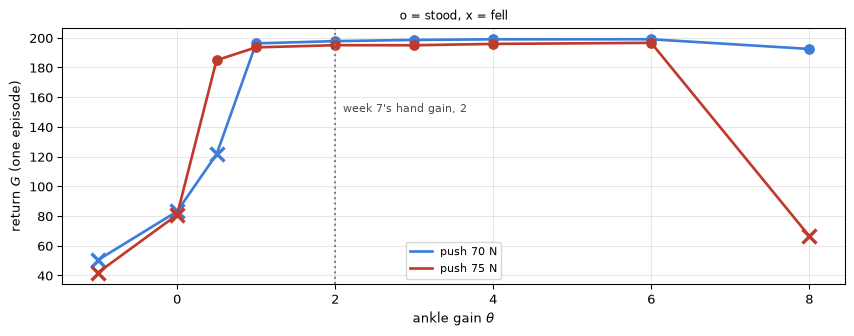

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for p, col in zip(pushes, ("#3b7dd8", "#c0392b")):
    G = np.array([g for g, _ in land[p]]); F = np.array([f for _, f in land[p]])
    ax.plot(thetas, G, "-", color=col, lw=2, label=f"push {p:.0f} N")
    ax.plot(np.array(thetas)[~F], G[~F], "o", color=col, ms=7)
    ax.plot(np.array(thetas)[F], G[F], "x", color=col, ms=10, mew=2.5)
ax.axvline(2.0, color="0.5", ls=":", lw=1.5); ax.text(2.1, 150, "week 7's hand gain, 2", fontsize=8, color="0.3")
ax.set_xlabel(r"ankle gain $\theta$"); ax.set_ylabel(r"return $G$ (one episode)")
ax.set_title("o = stood, x = fell", fontsize=9); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower center")
fig.tight_layout(); plt.show()

**An inverted U.** Too little gain (hold, $\theta = 0$) and the push
wins; too much and the ankles over-correct. In between there is a hill,
and its top is what we want the robot to find **without being shown this
picture**.

------------------------------------------------------------------------

## Reading the landscape

Measured with `lab.py`’s test (`--updates 0`, and the learned rules):

- **Holding the crouch** ($\theta = 0$) falls at 70 N and 75 N, left and
  right.
- **$\theta$ from 0.6 to 4 stands at 75 N.** A wide hilltop: the robot
  does not need the exact best gain, it needs *a* good one.
- **$\theta = 8$ falls at 75 N again**: too much gain over-corrects.
- **A negative $\theta$ falls at 60 N**: turning the ankles *with* the
  tilt helps the push.
- **Every $\theta$ falls at 80 N**: an ankle can only do so much. No
  learning fixes a push the strategy cannot survive.
- **Near the edge, falls are chaotic**: in the table, $\theta = 0.5$
  falls at 70 N yet stands at 75. Claim the shape of the hill, not one
  cell of it.
- **A roll gain on $g_y$**, tried as well, changed nothing at any of
  these pushes: the pitch strategy is what saves the robot.

What a learner needs from this picture is only the **slope** where it
stands: at $\theta = 0$, uphill is to the right. The rest of the deck is
about measuring that slope from episodes.

------------------------------------------------------------------------

## The policy gradient: Steps 1–3

Make the policy random,
${\color{#e8743b}{a}}\sim{\color{#3b7dd8}{\pi_\theta}}(\cdot\mid s)$, so
an episode $\tau$ has a probability $p_{\color{#3b7dd8}{\theta}}(\tau)$.

**Step 1 — write the average out.**
$\;J({\color{#3b7dd8}{\theta}}) = \sum_\tau p_{\color{#3b7dd8}{\theta}}(\tau)\,{\color{#2a9d5c}{G(\tau)}}$
(an integral for continuous actions; the steps are the same).

**Step 2 — differentiate.** ${\color{#2a9d5c}{G(\tau)}}$ is the score
written on episode $\tau$; only the probabilities depend on
${\color{#3b7dd8}{\theta}}$:
$\;\nabla_{\color{#3b7dd8}{\theta}} J = \sum_\tau \nabla_{\color{#3b7dd8}{\theta}}\,p_{\color{#3b7dd8}{\theta}}(\tau)\,{\color{#2a9d5c}{G(\tau)}}$.
No $p$ in front: not an average, so we cannot sample it.

**Step 3 — the log-derivative identity** puts $p$ back. The chain rule
gives $\nabla\log p = \nabla p / p$, so

$$\nabla_{\color{#3b7dd8}{\theta}}\,p_{\color{#3b7dd8}{\theta}}(\tau) = p_{\color{#3b7dd8}{\theta}}(\tau)\,\nabla_{\color{#3b7dd8}{\theta}}\log p_{\color{#3b7dd8}{\theta}}(\tau)
\quad\Longrightarrow\quad
\nabla_{\color{#3b7dd8}{\theta}} J = \mathbb{E}_{\tau}\big[\nabla_{\color{#3b7dd8}{\theta}}\log p_{\color{#3b7dd8}{\theta}}(\tau)\;{\color{#2a9d5c}{G(\tau)}}\big].$$

An average again: **run episodes, compute the bracket for each,
average.** $\nabla\log p$ is called the **score function**.

------------------------------------------------------------------------

## The policy gradient: Step 4, the simulator drops out

An episode is a chain of choices: the policy picks
${\color{#e8743b}{a_t}}$, MuJoCo picks $s_{t+1}$:

$$\log p_{\color{#3b7dd8}{\theta}}(\tau) = \log p(s_0) + \sum_t \log {\color{#3b7dd8}{\pi_\theta}}({\color{#e8743b}{a_t}}\mid s_t) + \sum_t \log P(s_{t+1}\mid s_t,{\color{#e8743b}{a_t}})$$

The first and last sums contain no ${\color{#3b7dd8}{\theta}}$: their
gradient is zero. **MuJoCo’s $P$ vanishes**; we need its samples, never
its formula:

$$\boxed{\;\nabla_{\color{#3b7dd8}{\theta}} J = \mathbb{E}\Big[\sum_t \nabla_{\color{#3b7dd8}{\theta}} \log {\color{#3b7dd8}{\pi_\theta}}({\color{#e8743b}{a_t}}\mid s_t)\;{\color{#2a9d5c}{G}}\Big]\;}\qquad\text{(REINFORCE)}$$

For our rule with Gaussian noise,
${\color{#e8743b}{a_t}} = {\color{#3b7dd8}{\theta}}\,g_{x,t} + {\color{#8e44ad}{\sigma}}\,{\color{#8e44ad}{\varepsilon_t}}$,
the score is one line:

$$\log{\color{#3b7dd8}{\pi_\theta}}({\color{#e8743b}{a}}\mid s) = -\frac{({\color{#e8743b}{a}} - {\color{#3b7dd8}{\theta}}\,g_x)^2}{2{\color{#8e44ad}{\sigma}}^2} + \text{const}
\qquad\Longrightarrow\qquad
\frac{\partial\log{\color{#3b7dd8}{\pi_\theta}}}{\partial{\color{#3b7dd8}{\theta}}} = \frac{{\color{#e8743b}{a}} - {\color{#3b7dd8}{\theta}}\,g_x}{{\color{#8e44ad}{\sigma}}^2}\,g_x = \frac{{\color{#8e44ad}{\varepsilon}}}{{\color{#8e44ad}{\sigma}}}\,g_x$$

Read it: **if the noise pushed the ankle one way and the episode paid
well, move ${\color{#3b7dd8}{\theta}}$ so the rule does that next
time.**

------------------------------------------------------------------------

## Why action noise hurts a balancing robot

REINFORCE learns only from the **noisy** robot. On a balancing robot,
fresh noise 50 times a second is not “trying something nearby”: it
shakes the ankles while the push is landing.

In [6]:
def noisy_episode(env, theta, push, sigma, rng):
    """lab.episode with fresh noise on the ankle command at every decision."""
    torso = env.model.body("torso_link").id
    obs, _ = env.reset(seed=0)
    while env.data.time < lab.SECONDS:
        a = np.zeros(12, np.float32)
        a[4] = a[10] = theta * obs[0] + sigma * rng.standard_normal()
        env.data.xfrc_applied[torso, :] = 0.0
        if 1.0 <= env.data.time < 1.2:
            env.data.xfrc_applied[torso, 1] = push
        obs, _, terminated, truncated, _ = env.step(np.clip(a, -1, 1))
        if terminated or truncated:
            return bool(terminated)
    return False

rng = np.random.default_rng(0)
for theta in (0.0, 2.0):
    falls = sum(noisy_episode(env, theta, 65.0, 0.3, rng) for _ in range(8))
    print(f"theta {theta:.0f}, 65 N: noise-free {'FELL' if lab.episode(env, theta, 65.0)[1] else 'stood'};"
          f"  with sigma 0.3 on the action, {falls} of 8 fell")

theta 0, 65 N: noise-free stood;  with sigma 0.3 on the action, 8 of 8 fell
theta 2, 65 N: noise-free stood;  with sigma 0.3 on the action, 5 of 8 fell

A push both mean rules survive (65 N) becomes a fall in most noisy
episodes, **even under the good gain 2**.

------------------------------------------------------------------------

## Explore in the parameter instead

**Measured while building `lab.py`:** REINFORCE with
${\color{#8e44ad}{\sigma}} = 0.3$ on the action had **every exploring
episode fall — 8 of 8 — and diverged**: the gradient compared one way of
falling with another. So keep the rule deterministic during an episode
and put the randomness **in ${\color{#3b7dd8}{\theta}}$**: try
${\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon}}$ for a
whole episode. A steady rule; a good try stands.

**The same identity, one level up.** Let the “policy” be the Gaussian
over gains,
$\vartheta \sim \mathcal N({\color{#3b7dd8}{\theta}}, {\color{#8e44ad}{\sigma}}^2)$,
and smooth the landscape with it:

$$J_{\color{#8e44ad}{\sigma}}({\color{#3b7dd8}{\theta}}) = \mathbb{E}_{\color{#8e44ad}{\varepsilon}}\big[J({\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon}})\big]
\qquad\Longrightarrow\qquad
\nabla J_{\color{#8e44ad}{\sigma}}({\color{#3b7dd8}{\theta}}) = \frac{1}{{\color{#8e44ad}{\sigma}}}\,\mathbb{E}_{\color{#8e44ad}{\varepsilon}}\big[J({\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon}})\;{\color{#8e44ad}{\varepsilon}}\big]$$

- the score of
  $\mathcal N({\color{#3b7dd8}{\theta}}, {\color{#8e44ad}{\sigma}}^2)$
  at
  $\vartheta = {\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon}}$
  is
  $(\vartheta - {\color{#3b7dd8}{\theta}})/{\color{#8e44ad}{\sigma}}^2 = {\color{#8e44ad}{\varepsilon}}/{\color{#8e44ad}{\sigma}}$
  — the previous slide’s formula, with one draw per episode instead of
  200
- $J_{\color{#8e44ad}{\sigma}}$ is $J$ blurred over a width
  ${\color{#8e44ad}{\sigma}}$: a small ${\color{#8e44ad}{\sigma}}$
  follows $J$’s slope closely, a large one sees only the hill’s overall
  shape

------------------------------------------------------------------------

## Antithetic pairs on a shared push

**Antithetic: try both
${\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon}}$ and
${\color{#3b7dd8}{\theta}} - {\color{#8e44ad}{\sigma\varepsilon}}$.**
Since $-{\color{#8e44ad}{\varepsilon}}$ is as likely as
${\color{#8e44ad}{\varepsilon}}$, averaging the two estimates gives

$$\hat g = \frac{1}{N}\sum_{i=1}^{N}\frac{\big[{\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon_i}}, {\color{#c0392b}{p_i}}) - {\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}} - {\color{#8e44ad}{\sigma\varepsilon_i}}, {\color{#c0392b}{p_i}})\big]\,{\color{#8e44ad}{\varepsilon_i}}}{2{\color{#8e44ad}{\sigma}}}
\qquad
{\color{#3b7dd8}{\theta}} \leftarrow {\color{#3b7dd8}{\theta}} + \eta\,\hat g$$

**Why it is a slope.** Taylor:
${\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}} \pm {\color{#8e44ad}{\sigma\varepsilon}}) \approx {\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}}) \pm {\color{#8e44ad}{\sigma\varepsilon}}\,{\color{#2a9d5c}{G}}'({\color{#3b7dd8}{\theta}})$,
so each term is
$\approx {\color{#8e44ad}{\varepsilon}}^2\,{\color{#2a9d5c}{G}}'({\color{#3b7dd8}{\theta}})$,
and $\mathbb E[{\color{#8e44ad}{\varepsilon}}^2] = 1$. A **finite
difference**, taken in a random direction.

- **The pair shares its push ${\color{#c0392b}{p_i}}$.** A hard push
  pays less than a soft one whatever the gain; within a pair that
  cancels, so ${\color{#2a9d5c}{G^+}} - {\color{#2a9d5c}{G^-}}$ is
  caused by the gain alone.
- **The common part of ${\color{#2a9d5c}{G}}$ cancels too**: the 200
  points of ALIVE that both tries collect never enter the step. That is
  the job a baseline does in REINFORCE, for free.
- In words: *try a bit more and a bit less on the same push; move toward
  the one that paid.*

------------------------------------------------------------------------

## The learner, from `lab.py`

The last line is $\hat g$: `(Gp - Gm) * eps`, averaged, over
`2 * SIGMA`. **This is the only line where the reward reaches
${\color{#3b7dd8}{\theta}}$.**

------------------------------------------------------------------------

## `learn`, line by line: code to maths

| code | the maths | note |
|------------------------|------------------------|------------------------|
| `rng = np.random.default_rng(seed)` | — | `--seed` fixes every push and every ${\color{#8e44ad}{\varepsilon}}$: a rerun repeats |
| `theta = 0.0` | ${\color{#3b7dd8}{\theta}} = 0$ | start: hold the crouch |
| `pushes = rng.choice([-1.0, 1.0], PAIRS) * rng.uniform(lo, hi, PAIRS)` | ${\color{#c0392b}{p_i}}$ = random sign × size uniform in \[`lo`, `hi`\] | the $\mathbb E_{\color{#c0392b}{p}}$ in $J({\color{#3b7dd8}{\theta}})$, sampled 8 times |
| `eps = rng.standard_normal(PAIRS)` | ${\color{#8e44ad}{\varepsilon_i}} \sim \mathcal N(0, 1)$ | one random direction per pair |
| `plus = [episode(env, theta + SIGMA * e, p) for e, p in zip(eps, pushes)]` | ${\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}} + {\color{#8e44ad}{\sigma\varepsilon_i}}, {\color{#c0392b}{p_i}})$ | a bit more gain |

*(continued on the next slide)*

------------------------------------------------------------------------

## `learn`, line by line: code to maths (cont.)

| code | the maths | note |
|------------------------|------------------------|------------------------|
| `minus = [episode(env, theta - SIGMA * e, p) for e, p in zip(eps, pushes)]` | ${\color{#2a9d5c}{G}}({\color{#3b7dd8}{\theta}} - {\color{#8e44ad}{\sigma\varepsilon_i}}, {\color{#c0392b}{p_i}})$ | a bit less, **on the same push** `p` |
| `Gp`, `Gm` (`r[0]` of each) | ${\color{#2a9d5c}{G^+_i}}$, ${\color{#2a9d5c}{G^-_i}}$ | `episode` returns `(G, fell, frames)` |
| `falls = sum(r[1] for r in plus + minus)` | — | printed only (out of 16); the update never sees it |
| `theta += LR * float(np.mean((Gp - Gm) * eps)) / (2 * SIGMA)` | ${\color{#3b7dd8}{\theta}} \leftarrow {\color{#3b7dd8}{\theta}} + \eta\,\hat g$ | `np.mean` is $\frac1N\sum_i$, `2 * SIGMA` is $2{\color{#8e44ad}{\sigma}}$ |

One update = 2 × `PAIRS` = 16 episodes; the printed `theta` is the value
*before* that update.

------------------------------------------------------------------------

## Learning, live

Ten updates (the lab runs twenty), seed 0, training pushes 60–80 N:

In [8]:
t0 = time.time()
theta = lab.learn(env, updates=10, lo=60.0, hi=80.0, seed=0)
print(f"theta after 10 updates = {theta:.2f}   ({time.time() - t0:.0f} s, {10 * 2 * lab.PAIRS} episodes)")

update   theta  mean return   falls
     0    0.00        104.4  12/16
     1    0.68        143.3   7/16
     2    1.08        193.6   0/16
     3    1.09        167.4   4/16
     4    1.08        158.3   5/16
     5    1.23        176.0   3/16
     6    1.39        183.9   2/16
     7    1.68        197.0   0/16
     8    1.69        179.8   2/16
     9    1.69        191.4   1/16
theta after 10 updates = 1.59   (24 s, 160 episodes)

**Measured with `lab.py`** (20 updates of 8 pairs, about 50 s each):
${\color{#3b7dd8}{\theta}}$ 0 → **1.82 / 2.00 / 1.53** for seeds 0 / 1 /
2. Week 7’s hand-written ankle gain is 2: the robot found it from reward
alone.

------------------------------------------------------------------------

## The test, from `lab.py`

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `rules` | a dict, name → gain, e.g. `{"hold (0)": 0.0, "hand (2)": 2.0, ...}` | one column per rule |
| `for f in forces:` | each test force, e.g. 70, 75, 80 N | `--test` sets them |
| `((f"{f:g} N left", f), (f"{f:g} N right", -f))` | every force twice: $+{\color{#c0392b}{p}}$ (left) and $-{\color{#c0392b}{p}}$ (right) | a rule must survive both sides |
| `episode(env, th, push)[1]` | runs one episode, keeps only `fell` | the test asks *did it stand*, not ${\color{#2a9d5c}{G}}$ |

No learning and no randomness inside: every rule meets the same pushes,
so on one machine the table repeats exactly.

------------------------------------------------------------------------

## The test: fixed pushes, three rules

In [10]:
lab.test(env, {"hold (0)": 0.0, "hand (2)": 2.0, f"learned ({theta:.2f})": theta}, [70.0, 75.0, 80.0])


        push       hold (0)       hand (2)  learned (1.59)
   70 N left           FELL          stood          stood
  70 N right           FELL          stood          stood
   75 N left           FELL          stood          stood
  75 N right           FELL          stood          stood
   80 N left           FELL           FELL           FELL
  80 N right           FELL           FELL           FELL

- `test` uses pushes the learner never chose: the same 70 / 75 / 80 N
  for every rule, left and right.
- The seeds land on different gains (1.53–2.00), and all of them sit on
  the hilltop of the landscape: **any gain from 0.6 to 4 stands at 75
  N** (measured). A learner does not have to find the top exactly, only
  the hill.
- 80 N defeats every rule: the limit belongs to the strategy, not to the
  learner.

------------------------------------------------------------------------

## The reward is a design decision

The learner climbs whatever ${\color{#2a9d5c}{r}}$ pays for. It cannot
tell you whether that is what you wanted. Today’s reward pays for
**staying up** (ALIVE), **staying vertical** (UPRIGHT) and, a little,
**quiet ankles** (EFFORT).

**Questions for the lab. Write your prediction before you run.**

1.  **`ALIVE = 0`.** Every remaining term is a penalty, and falling
    *ends* the penalties. Is staying up still worth more than falling
    early? Is there still a reason to learn?
2.  **Reward only survival**: return 1.0 on every step, 0 on the step it
    falls. The landscape becomes flat on the hilltop. Does the learner
    still move, and where does it stop?
3.  **`UPRIGHT = 1000`.** Does the learned ${\color{#3b7dd8}{\theta}}$
    change, or only the size of the numbers? (Remember `LR` multiplies a
    difference of returns.)
4.  **`--pushes 30 50`**: pushes nobody falls from. Is there anything to
    learn?
5.  **`SIGMA = 0.05` or `3`**: tries too close together, or too far
    apart (look back at the landscape).

These are questions, not results: **nobody has measured them for you.**
Your table is the answer.

------------------------------------------------------------------------

## PPO: the same idea, scaled to networks

A real locomotion policy has $10^5$ parameters, not one. PPO keeps
REINFORCE’s action noise (a network cannot try $\pm$ in each of $10^5$
directions on one push) and fixes its noise with two parts:

- a **value baseline**: a second network ${V(s)}$ predicts the return,
  and the update uses
  ${\color{#2a9d5c}{A_t}} = {\color{#2a9d5c}{G_t}} - V(s_t)$ (our pair
  subtracted the common return for free);
- a **clipped ratio**:
  $\rho_t = {\color{#3b7dd8}{\pi_\theta}}({\color{#e8743b}{a_t}}\mid s_t)/{\color{#3b7dd8}{\pi_{\text{old}}}}({\color{#e8743b}{a_t}}\mid s_t)$
  kept within $1 \pm 0.2$, so one batch is reused for several small,
  safe steps.

**Measured on the G1 (`G1WalkEnv`, stable-baselines3 PPO, 30k steps):**

| run | return (deterministic) |
|------------------------------------|------------------------------------|
| untrained: residual actions start near zero, so it holds the crouch | 774.3 |
| PPO, default exploration (action std 1.0 on a $[-1, 1]$ action) | **94.7** — worse than doing nothing |
| PPO, `log_std_init = -2` (std 0.135) | 776 — learns not to fall, not to walk (walking is worth 1250) |

The cause was **exploration noise, not the reward**: the untrained mean
action survives 500 steps, the sampled one 38. Today’s lesson, at scale.

------------------------------------------------------------------------

## How `lab.py` runs: `main`, top to bottom

1.  **Flags.** `argparse` reads `--updates` (default 20),
    `--pushes LO HI` (60 80), `--test` (70 75 80), `--seed` (0) and
    `--no-viewer`.
2.  **The environment.** `from soc4180.envs import G1WalkEnv` sits in a
    `try`: without gymnasium it tells you to run `uv sync --extra rl`
    once, and stops. Then `env = G1WalkEnv()`: one G1, reused by every
    episode.
3.  **Learn.**
    `theta = learn(env, args.updates, *args.pushes, args.seed)` prints
    the update table, then `learned theta = ... in ... s`.
4.  **Test.**
    `test(env, {"hold (0)": 0.0, "hand (2)": 2.0, f"learned ({theta:.2f})": theta}, args.test)`:
    three columns, the same pushes.
5.  **Stop here** if `args.no_viewer or soc4180.is_colab()`: Colab has
    no window.

------------------------------------------------------------------------

## How `lab.py` runs: the replay, and what you type

1.  **Record.**
    `_, fell, frames = episode(env, theta, push, record=True)` with
    `push = args.test[0]`: the learned ${\color{#3b7dd8}{\theta}}$ under
    the first test push, to the left.
2.  **Replay.**
    `soc4180.launch_viewer(env.model, env.data, passive=True)`, then for
    each saved pose
    `env.data.qpos[:] = q; mujoco.mj_forward(env.model, env.data); viewer.sync()`
    and `time.sleep(env.control_dt)`: no physics is re-run, the
    recording is drawn at real speed and repeats until you close the
    window.

``` bash
uv run weeks/08-learning-to-act/lab.py                 # all seven steps
uv run weeks/08-learning-to-act/lab.py --no-viewer     # steps 1-5
uv run weeks/08-learning-to-act/lab.py --updates 0     # learn nothing: test theta = 0
```

------------------------------------------------------------------------

## Lab class on your laptop

``` bash
uv sync --extra rl                                   # once: gymnasium (the G1 environment)
uv run weeks/08-learning-to-act/lab.py               # learn (~1 min), test, then replay in the viewer
uv run weeks/08-learning-to-act/lab.py --no-viewer   # headless
uv run weeks/08-learning-to-act/lab.py --updates 0   # no learning: test the starting rule
uv run weeks/08-learning-to-act/lab.py --pushes 30 50 --seed 1
```

**What you change** (one at a time, prediction first), all in `lab.py`:

| where | what |
|------------------------------------|------------------------------------|
| `reward()` and `ALIVE`, `UPRIGHT`, `EFFORT` | what the robot is paid for |
| `SIGMA`, `LR`, `PAIRS` | how far apart the tries are, how big a step, how many pairs per update |
| `--pushes LO HI`, `--test`, `--seed`, `--updates` | the training world, the exam, the randomness, the budget |

------------------------------------------------------------------------

## Lab class: what you should see

1.  **The update table**: `update  theta  mean return  falls`.
    ${\color{#3b7dd8}{\theta}}$ climbs from 0; the falls column empties
    as it does. With the shipped settings, seed 0 ends at **1.82**
    (seeds 1, 2: 2.00, 1.53).
2.  **The test table**: hold (0) **FELL** at 70 and 75 N; hand (2) and
    learned **stood**; all three **FELL** at 80 N.
3.  **The replay**: the learned rule under the first test push (70 N to
    the left). Orbit the camera and watch the ankles turn against the
    tilt.

## Lab class: try

One change at a time, prediction first (from `lab.py`’s docstring):

| \# | change | ask |
|-------------------|---------------------------|---------------------------|
| 1 | `ALIVE = 0` | is there still a reason to learn? |
| 2 | `reward` returns 1.0, or 0 on the step it falls | what does it learn now? |
| 3 | `UPRIGHT = 1000` | does the learned ${\color{#3b7dd8}{\theta}}$ change? |
| 4 | `--pushes 30 50` | pushes nobody falls from: anything to learn? |
| 5 | `SIGMA = 0.05` or `3` | tries too close together, or too far apart |

Show the instructor the two tables and say in one sentence **why** they
differ from the shipped run.

------------------------------------------------------------------------

## For your term project: what builds on this week

The term project (weeks 12–15) is described in
[`weeks/projects/README.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/README.md);
the list is
[`weeks/projects/catalogue.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/catalogue.md).
It uses only `soc4180` and what `uv.lock` installs.

| Project | What it takes from this week |
|------------------------------------|------------------------------------|
| **P9** Reward design for stepping: diagnose, don’t promise | the reward is a design decision; `G1WalkEnv(reward_weights=…)`; PPO stands still at 30k steps |
| **P13** A table that balances | a learner judged against a known answer: week 7’s 72.12, today’s hand gain 2 and the push test |
| **P3** Balance from the robot’s own senses | the ankle rule ${\color{#e8743b}{a}} = {\color{#3b7dd8}{\theta}}\,g_x$ read from the *true* tilt; does it survive a noisy IMU (week 6)? |
| **P14** Your own proposal | anything here, if it states a measurable prediction |

Measured limits, so do not promise past them: every gain falls at 80 N;
PPO at a laptop budget learns not to fall, not to walk.

------------------------------------------------------------------------

## For your term project: the method

The habits this deck used, written into every experiment you hand in:

1.  **A prediction before the run.** The number, or the direction, you
    expect and why: “the learned $\theta$ will stay near 2 with
    `UPRIGHT = 1000`” is a prediction.
2.  **A twin run with one change.** Same seed, same pushes, same test;
    one setting different. Without the twin, a number has nothing to be
    compared with.
3.  **`results.csv`**: one row per run — what changed, seed, learned
    ${\color{#3b7dd8}{\theta}}$, falls at each test push — written by
    the script, not copied by hand.
4.  **A `CHECK` line** per prediction, decided before the final run and
    printed as `CHECK PASS` or `CHECK FAIL`. A failed prediction is
    reported, not deleted. Format:
    [`weeks/projects/README.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/README.md).

**Never grade convergence; grade the diagnosis.** A run that fails and
is explained with measurements is a good project.

**Next week (9): scale and robustness.** One gain learned in a minute;
next, many parameters, many robots in parallel, and a world that varies.